# Multi-Brand Marketing Campaign Performance Analysis & Prediction
Nykaa · Purplle · Tira — end-to-end pipeline walk-through.

This notebook explains each step and shows its outputs. All logic lives in the `src/` package, so the notebook, `run_pipeline.py` and the Streamlit app share exactly the same code. Model training (steps 5–6) is run by `python run_pipeline.py`; here we load the saved models and results.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, joblib
from IPython.display import Image, display
from src import config as C, preprocessing, features, eda
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

## 1. Data collection — CSV ➜ DataFrame

In [2]:
raw = preprocessing.load_raw()
print(raw.shape)
raw.drop(columns='_row').head()

(166665, 18)


,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
0,Nykaa,NY-CMP-1000,Social Media,College Students,21.0,"WhatsApp, YouTube",57804.0,6156.0,3616.0,2355.0,1867515.0,NaN,6.14,Hindi,20.98,College Students,29-04-2025
1,Nykaa,NY-CMP-1001,Paid Ads,Tier 2 City Customers,18.0,YouTube,91801.0,3321.0,1971.0,1357.0,1046247.0,180.83,3.26,Hindi,7.24,College Students,06-04-2025
2,Nykaa,NY-CMP-1002,Influencer,Youth,23.0,"WhatsApp, Google, YouTube",15536.0,2182.0,952.0,755.0,197055.0,90.60,NaN,English,25.03,College Students,14-01-2025
3,Nykaa,NY-CMP-1003,Email,Working Women,18.0,"YouTube, Facebook, Instagram",88114.0,8413.0,2231.0,947.0,376906.0,249.07,0.60,Hindi,13.15,NaN,04-06-2025
4,Nykaa,NY-CMP-1004,Paid Ads,College Students,10.0,"Facebook, Instagram",96871.0,3743.0,2060.0,1258.0,518296.0,228.60,0.80,Hindi,7.29,Tier 2 City Customers,29-12-2024


In [3]:
raw.drop(columns='_row').info()

<class 'pandas.DataFrame'>
RangeIndex: 166665 entries, 0 to 166664
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Brand             166665 non-null  str    
 1   Campaign_ID       161248 non-null  str    
 2   Campaign_Type     158307 non-null  str    
 3   Target_Audience   158493 non-null  str    
 4   Duration          158342 non-null  float64
 5   Channel_Used      158383 non-null  str    
 6   Impressions       158441 non-null  float64
 7   Clicks            158441 non-null  float64
 8   Leads             158575 non-null  float64
 9   Conversions       158665 non-null  float64
 10  Revenue           158361 non-null  float64
 11  Acquisition_Cost  158504 non-null  float64
 12  ROI               158367 non-null  float64
 13  Language          158366 non-null  str    
 14  Engagement_Score  158584 non-null  float64
 15  Customer_Segment  158490 non-null  str    
 16  Date              158566 non-nu

In [4]:
nulls = raw.drop(columns='_row').isna().sum().to_frame('nulls')
nulls['%'] = (nulls.nulls / len(raw) * 100).round(2)
nulls.T

,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
nulls,0.0,5417.00,8358.00,8172.0,8323.00,8282.00,8224.00,8224.00,8090.00,8000.0,8304.00,8161.0,8298.00,8299.00,8081.00,8175.00,8099.00
%,0.0,3.25,5.01,4.9,4.99,4.97,4.93,4.93,4.85,4.8,4.98,4.9,4.98,4.98,4.85,4.91,4.86


### Discovering the data's structure
Two exact identities hold on >99.99% of complete rows:

* **ROI = (Revenue − Acquisition_Cost × Conversions) / (Acquisition_Cost × Conversions)** → `Acquisition_Cost` is the cost **per conversion**; total spend = Acquisition_Cost × Conversions.
* **Engagement_Score = (Clicks + Leads + Conversions) / Impressions × 100**

These allow exact recovery of a missing value when only one member of an identity is null.

In [5]:
d = raw.dropna()
cost = d.Acquisition_Cost * d.Conversions
print('ROI identity holds:', ((d.Revenue - cost) / cost - d.ROI).abs().lt(0.011).mean().round(5))
eng = (d.Clicks + d.Leads + d.Conversions) / d.Impressions * 100
print('Engagement identity holds:', (eng - d.Engagement_Score).abs().lt(0.011).mean().round(5))
print('Missing Campaign_IDs are sequential gaps:', raw.Campaign_ID.isna().sum())

ROI identity holds: 0.99948
Engagement identity holds: 1.0
Missing Campaign_IDs are sequential gaps: 5417


## 2. Data cleaning & preprocessing
1. Reconstruct missing `Campaign_ID` (IDs are sequential: `<prefix>-<1000 + row>`)
2. Remove duplicate rows / IDs
3. Type conversion (dates, ints) and text standardisation (channel lists sorted & de-duplicated)
4. **Validate and correct ROI** against the identity
5. Exact recovery of single missing values via both identities
6. Drop rows whose financials can't be made consistent (≥ 2 of Revenue / Cost / Conversions / ROI missing)
7. Remaining funnel gaps → brand median conversion ratios, then funnel monotonicity enforced
8. Duration → brand median; categoricals → brand mode; missing channels → `Unknown`; missing dates → sampled from the brand's observed dates (keeps seasonality)

In [6]:
clean, log = preprocessing.clean(raw)
for k, v in log.items():
    if k != 'raw_nulls': print(f'{k:<40} {v}')

raw_rows                                 166665
campaign_id_reconstructed                5417
campaign_id_mismatch                     0
duplicates_removed                       0
roi_values_corrected                     25
engagement_values_corrected              0
recovered_via_roi_identity               23279
recovered_via_engagement_identity        34345
rows_dropped_unrecoverable_financials    1435
funnel_filled_by_median_ratio            2320
duration_median_filled                   8254
categorical_mode_filled                  {'Campaign_Type': 8283, 'Target_Audience': 8112, 'Language': 8225, 'Customer_Segment': 8105}
channel_unknown_filled                   8221
date_sampled_filled                      8018
clean_rows                               165230
remaining_nulls                          0


In [7]:
print('Remaining nulls:', clean.isna().sum().sum(), '| duplicates:', clean.duplicated().sum())
clean.dtypes.to_frame('dtype').T

Remaining nulls: 0 | duplicates: 0


,Brand,Campaign_ID,Campaign_Type,Target_Audience,Duration,Channel_Used,Impressions,Clicks,Leads,Conversions,Revenue,Acquisition_Cost,ROI,Language,Engagement_Score,Customer_Segment,Date
dtype,str,str,str,str,int64,str,int64,int64,int64,int64,float64,float64,float64,str,float64,str,datetime64[us]


## 3. Feature engineering
* **Profit_Flag** = 1 if ROI > 0 else 0
* **Multi-label encoding** of `Channel_Used` → `Ch_Email … Ch_YouTube` + `Channel_Count`
* Funnel / cost features: CTR, Lead_Rate, Conversion_Rate, Total_Cost, Cost_per_Click, Revenue_per_Conversion, Month, Day_of_Week

In [8]:
feat = features.add_profit_flag(features.add_features(clean))
feat[['Campaign_ID','Channel_Used'] + features.CHANNEL_COLS + ['Channel_Count','ROI','Profit_Flag']].head()

,Campaign_ID,Channel_Used,Ch_Email,Ch_Facebook,Ch_Google,Ch_Instagram,Ch_WhatsApp,Ch_YouTube,Channel_Count,ROI,Profit_Flag
0,NY-CMP-1000,"WhatsApp, YouTube",0,0,0,0,1,1,2,6.14,1
1,NY-CMP-1001,YouTube,0,0,0,0,0,1,1,3.26,1
2,NY-CMP-1002,"Google, WhatsApp, YouTube",0,0,1,0,1,1,3,1.88,1
3,NY-CMP-1003,"Facebook, Instagram, YouTube",0,1,0,1,0,1,3,0.60,1
4,NY-CMP-1004,"Facebook, Instagram",0,1,0,1,0,0,2,0.80,1


In [9]:
feat.Profit_Status.value_counts(normalize=True).round(3)

Profit_Status
Profit    0.76
Loss      0.24
Name: proportion, dtype: float64

## 4. Exploratory data analysis
Figures are generated by `src/eda.py` (also served live in the Streamlit dashboard).

In [10]:
tables = eda.run_eda(feat)
tables['brand_kpis'].round(2)

,Campaigns,Total_Revenue,Total_Spend,Net_Profit,Median_ROI,Mean_ROI,Profit_Rate_%,Avg_CTR_%,Avg_Conv_Rate_%,Avg_Revenue_per_Conv,Avg_Cost_per_Conv,Portfolio_ROI
Brand,,,,,,,,,,,,
Nykaa,55053,2.840782e+10,9.609535e+09,1.879828e+10,1.24,2.72,75.95,8.51,55.02,499.48,377.27,1.96
Purplle,55079,2.829047e+10,9.634584e+09,1.865588e+10,1.23,2.68,75.80,8.50,54.86,499.51,376.59,1.94
Tira,55098,2.821688e+10,9.633078e+09,1.858380e+10,1.24,2.68,76.31,8.50,54.98,499.56,374.37,1.93


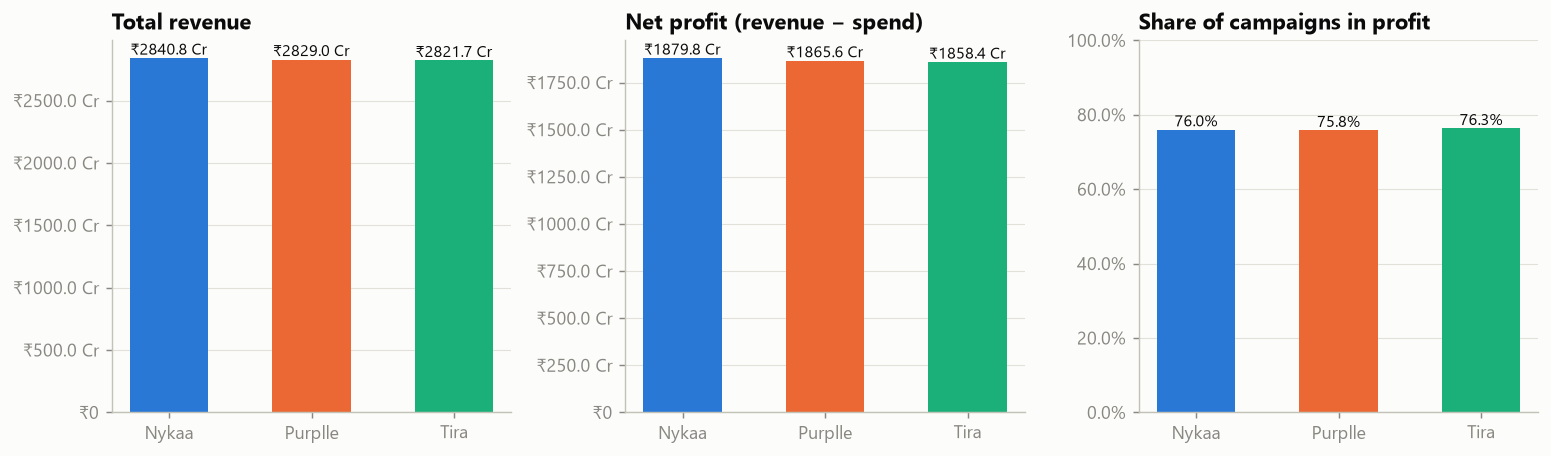

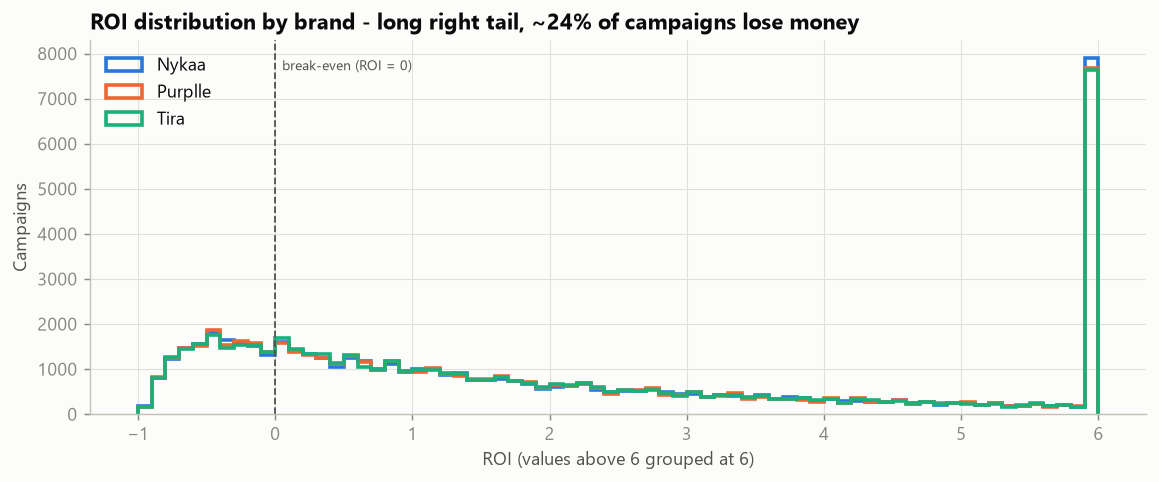

In [11]:
display(Image(str(C.FIGURES_DIR / 'eda_01_brand_overview.png')))
display(Image(str(C.FIGURES_DIR / 'eda_02_roi_distribution.png')))

### Campaign type × brand

,Campaigns,Median_ROI,Profit_Rate_%,Avg_Revenue,Avg_Spend,Avg_Engagement
Campaign_Type,,,,,,
Paid Ads,34186,1.26,76.23,519072.11,174903.35,13.78
Social Media,31241,1.24,76.62,515704.23,174519.58,13.82
SEO,31284,1.23,75.74,510869.00,174813.00,13.70
Email,34212,1.22,75.78,513176.58,174548.75,13.72
Influencer,34307,1.21,75.76,510689.54,175045.14,13.80


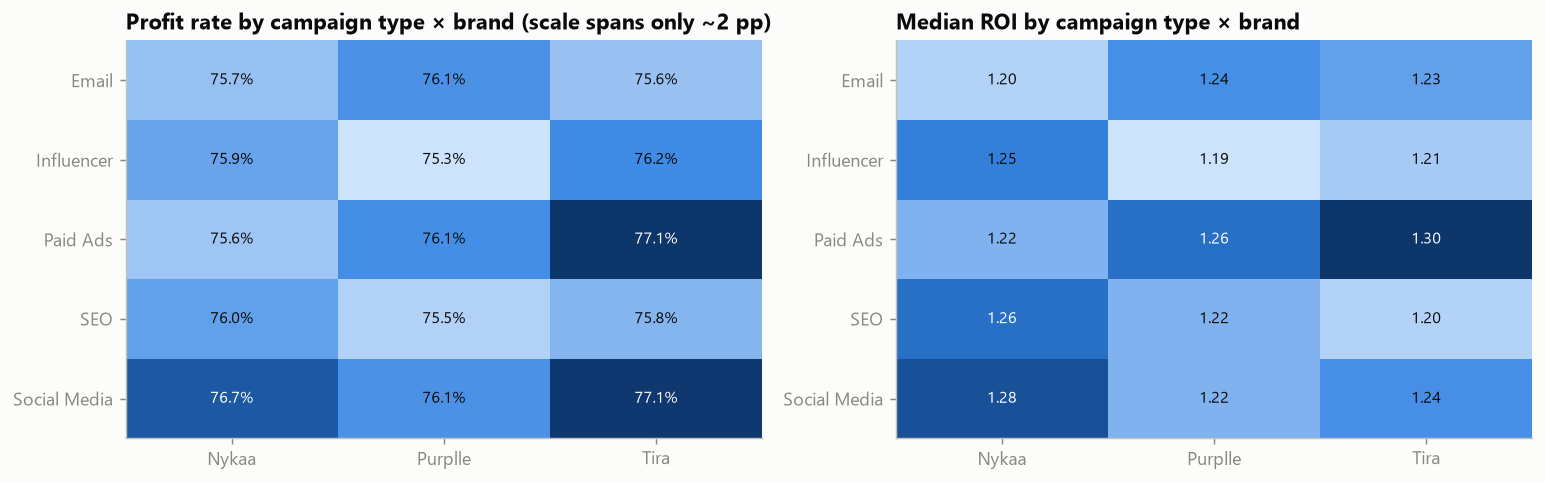

In [12]:
display(tables['campaign_type'].round(2))
display(Image(str(C.FIGURES_DIR / 'eda_03_campaign_type_brand.png')))

### Channel-wise effectiveness (multi-channel campaigns counted once per channel)

,Campaigns,Median_ROI,Profit_Rate_%,Avg_Revenue,Avg_Spend,Avg_Engagement
Channel,,,,,,
Instagram,52399,1.26,76.30,517393.49,174602.45,13.81
Email,52400,1.25,76.21,516984.97,174382.29,13.84
Facebook,52371,1.23,76.06,513647.96,175226.88,13.73
WhatsApp,52271,1.23,76.19,513598.86,175066.19,13.80
Google,52376,1.22,75.81,512127.54,174436.15,13.72
YouTube,52317,1.22,75.96,511938.37,174685.87,13.72


,Campaigns,Median_ROI,Profit_Rate_%,Avg_Revenue,Avg_Spend,Avg_Engagement
Channel_Count,,,,,,
3,52399,1.24,76.12,514218.91,174645.78,13.76
2,52327,1.24,76.07,514499.87,174890.49,13.79
1,52283,1.23,76.02,514041.44,174680.95,13.76
0,8221,1.22,75.06,507571.27,175355.13,13.66


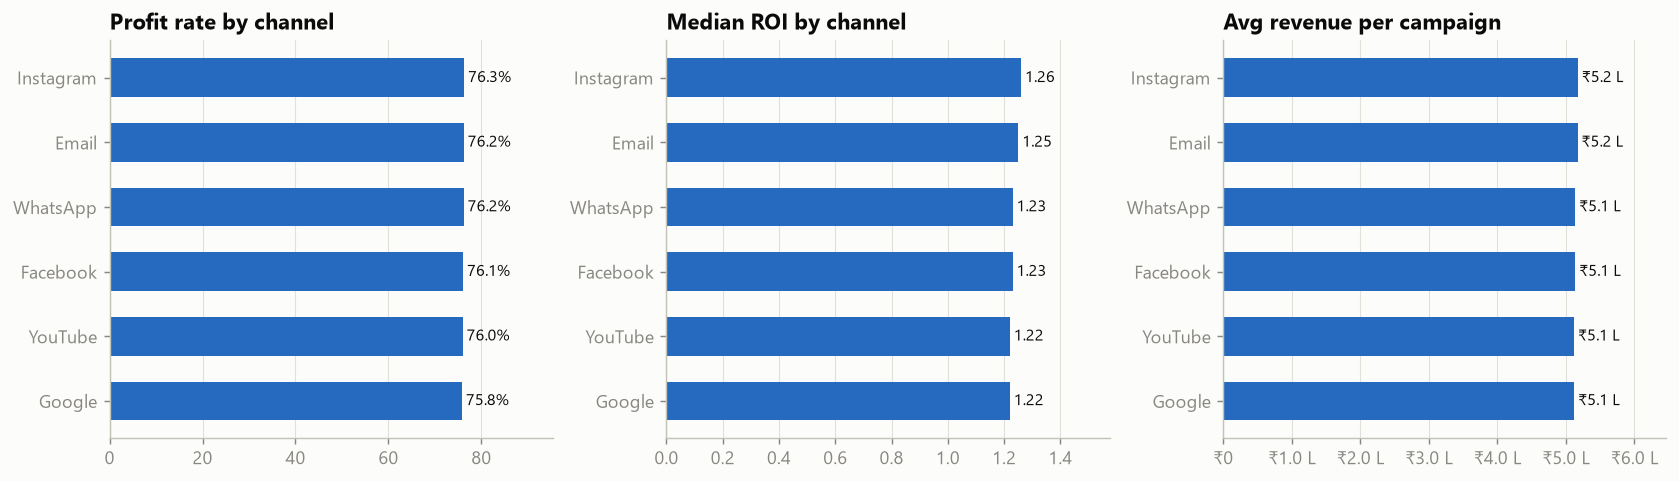

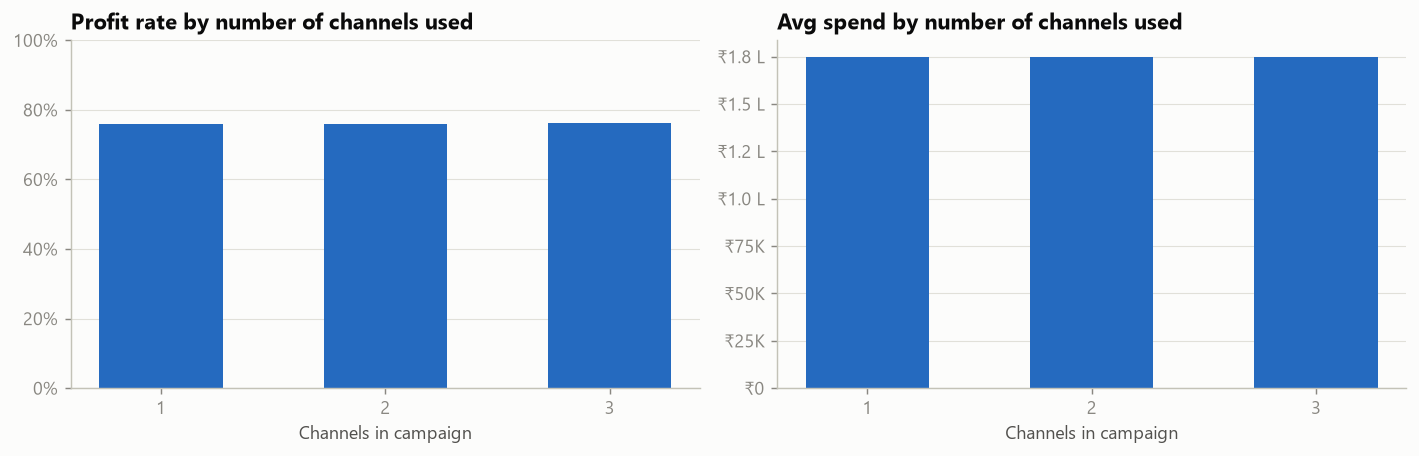

In [13]:
display(tables['channel'].round(2))
display(tables['channel_count'].round(2))
display(Image(str(C.FIGURES_DIR / 'eda_04_channel_effectiveness.png')))
display(Image(str(C.FIGURES_DIR / 'eda_05_channel_count.png')))

### Spend, clicks, revenue and ROI relationships

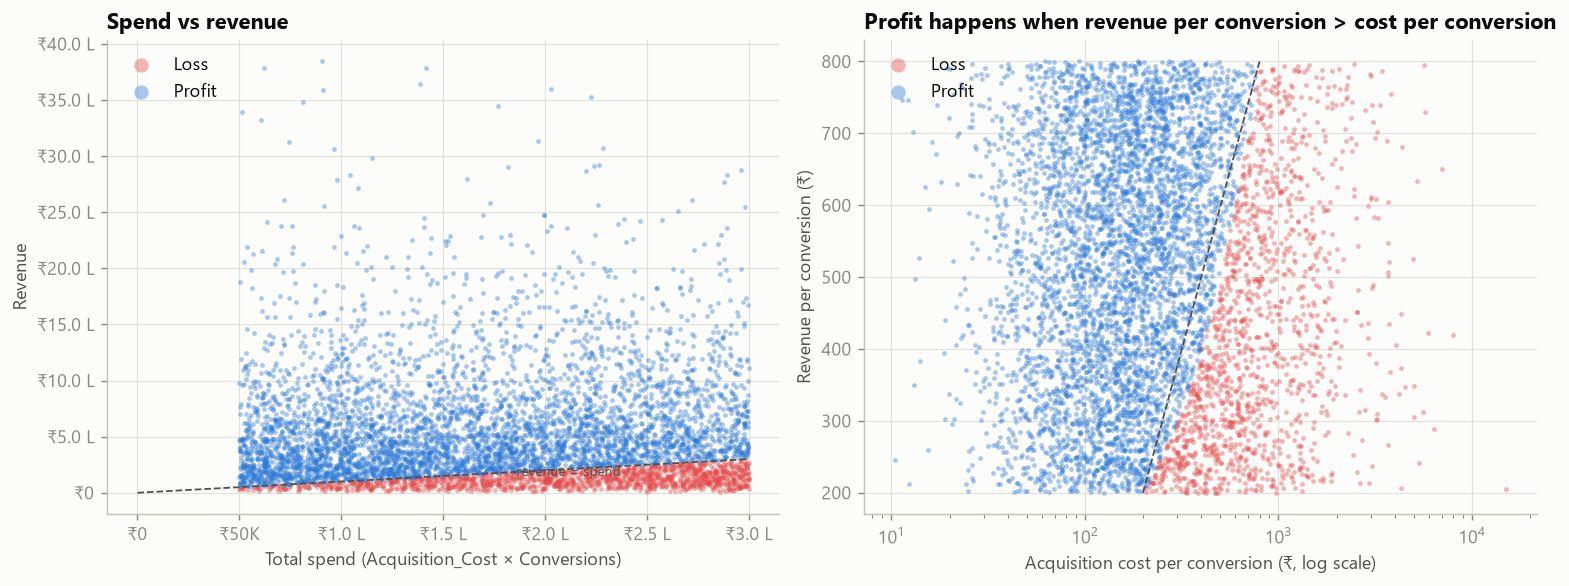

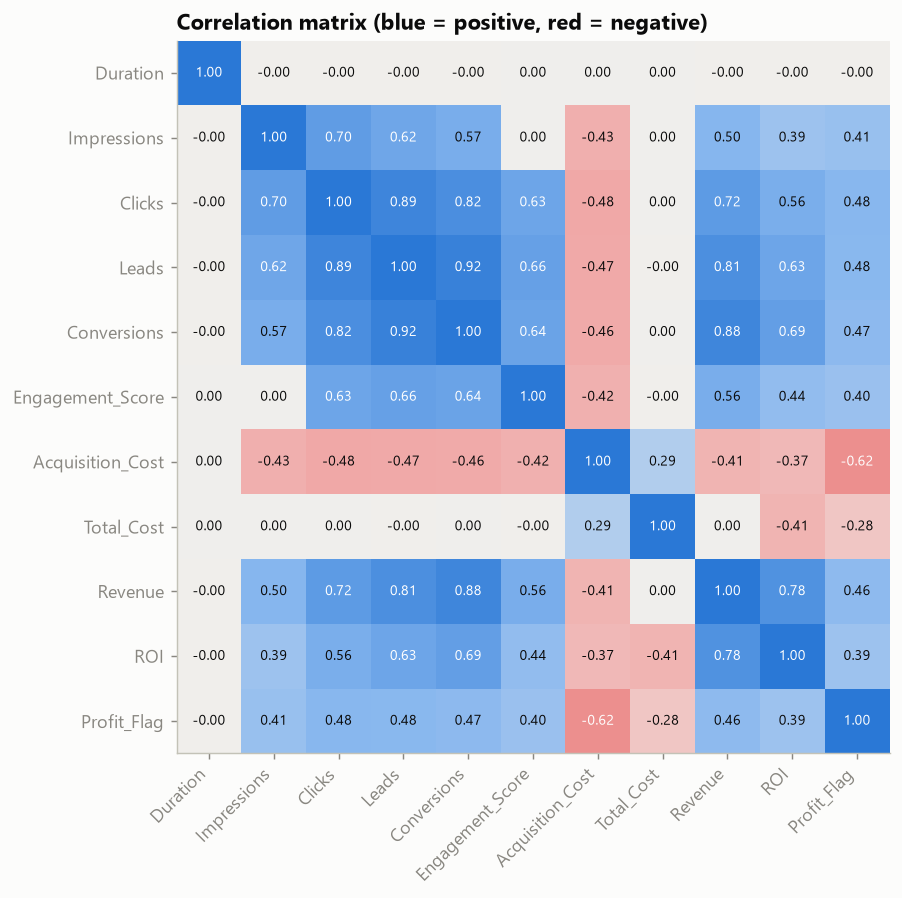

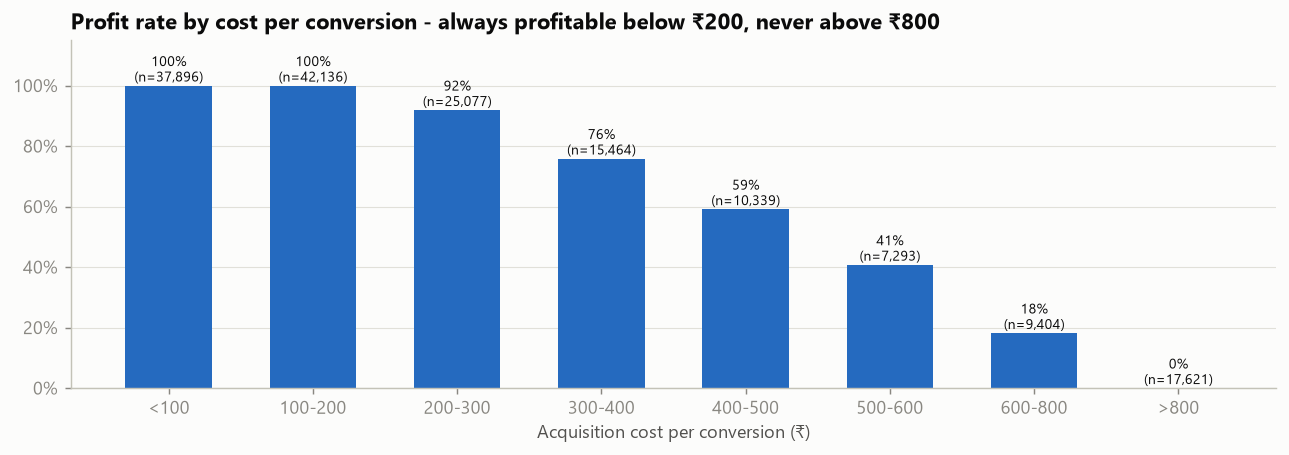

In [14]:
display(Image(str(C.FIGURES_DIR / 'eda_06_spend_vs_revenue.png')))
display(Image(str(C.FIGURES_DIR / 'eda_07_correlation.png')))
display(Image(str(C.FIGURES_DIR / 'eda_10_cost_per_conversion_bands.png')))

### Trend, audience and language

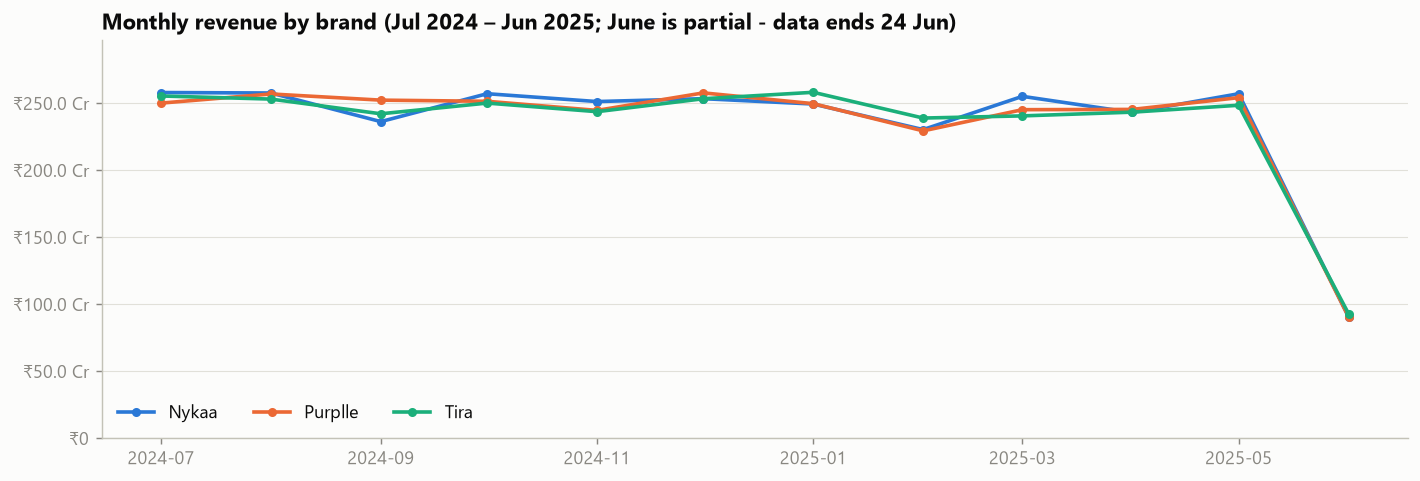

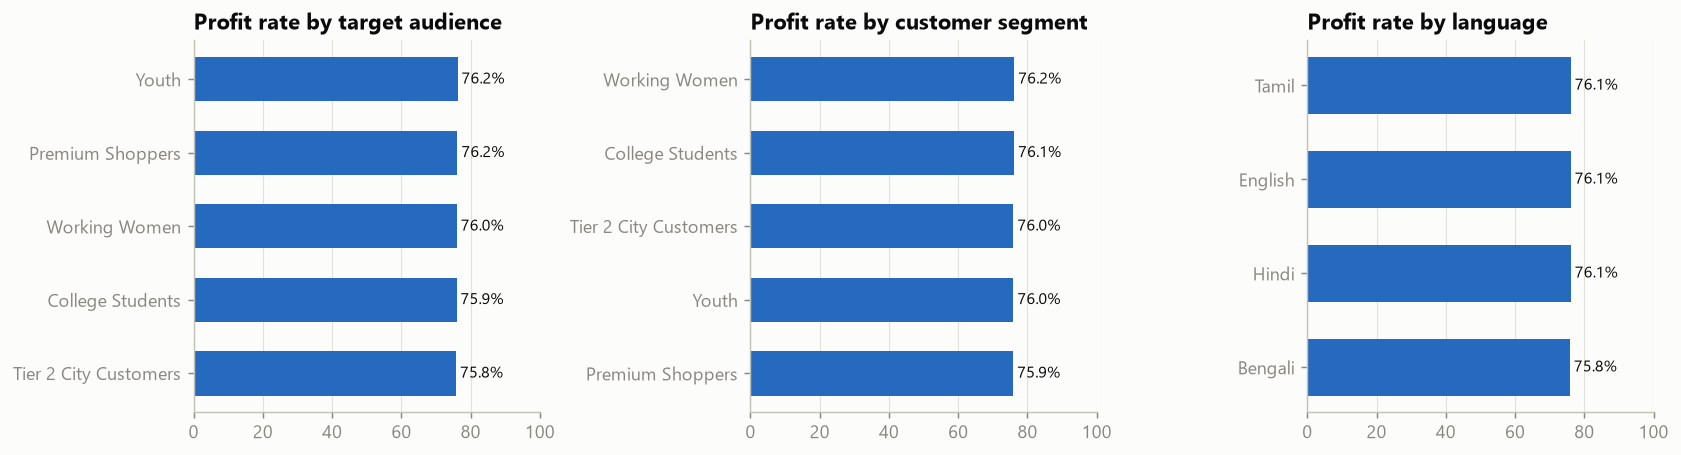

In [15]:
display(Image(str(C.FIGURES_DIR / 'eda_08_monthly_revenue.png')))
display(Image(str(C.FIGURES_DIR / 'eda_09_audience_language.png')))

### Top- and low-performing campaigns

In [16]:
display(tables['top10_roi'])
display(tables['bottom10_roi'])

,Campaign_ID,Brand,Campaign_Type,Channel_Used,Revenue,Total_Cost,ROI
155162,TI-CMP-46406,Tira,Social Media,"Google, Instagram",4041864.0,50323.36,79.32
11912,NY-CMP-13007,Nykaa,Paid Ads,"Email, Facebook, YouTube",4579910.0,60708.88,74.42
127319,TI-CMP-18349,Tira,Paid Ads,"Facebook, Google",4045290.0,55294.56,72.16
95678,PU-CMP-41973,Purplle,Paid Ads,Instagram,3467292.0,51088.86,66.87
21500,NY-CMP-22689,Nykaa,Influencer,"Instagram, YouTube",3821485.0,56764.20,66.32
48285,NY-CMP-49715,Nykaa,Paid Ads,WhatsApp,3717208.0,56341.12,64.98
118812,TI-CMP-9758,Tira,Email,"Instagram, WhatsApp",3392874.0,51551.70,64.80
25129,NY-CMP-26356,Nykaa,Paid Ads,Facebook,3363384.0,51641.76,64.14
83985,PU-CMP-30181,Purplle,SEO,WhatsApp,3278224.0,50460.88,63.96
62978,PU-CMP-8989,Purplle,SEO,"Email, YouTube",3668850.0,58683.00,61.52


,Campaign_ID,Brand,Campaign_Type,Channel_Used,Revenue,Total_Cost,ROI
137926,TI-CMP-29039,Tira,Email,Email,3895.0,285722.00,-0.99
129696,TI-CMP-20738,Tira,Influencer,"Email, Instagram, WhatsApp",6072.0,279918.10,-0.98
8294,NY-CMP-9361,Nykaa,Social Media,"Email, WhatsApp",7584.0,229994.88,-0.97
23198,NY-CMP-24406,Nykaa,Paid Ads,"Facebook, YouTube",6183.0,183750.12,-0.97
78622,PU-CMP-24764,Purplle,Influencer,Unknown,7350.0,274769.95,-0.97
85819,PU-CMP-32028,Purplle,Email,Email,9072.0,271795.86,-0.97
110491,TI-CMP-1359,Tira,Influencer,"Facebook, Instagram, WhatsApp",9180.0,299162.88,-0.97
117997,TI-CMP-8939,Tira,Social Media,"Email, Instagram, WhatsApp",8695.0,248557.86,-0.97
125003,TI-CMP-16012,Tira,Paid Ads,Google,9625.0,286408.15,-0.97
164879,TI-CMP-56201,Tira,Email,Unknown,6987.0,251640.97,-0.97


## 5–6. Model building & evaluation
* 80/20 stratified train/test split (random_state = 42)
* **Regression (Revenue)**: Linear Regression, Decision Tree, Random Forest, Hist Gradient Boosting
* **Classification (Profit_Flag)**: Logistic Regression, Decision Tree, Random Forest, Hist Gradient Boosting
* Hyper-parameters tuned with `RandomizedSearchCV` (3-fold CV)
* **No leakage**: ROI is never a classifier input, and no Revenue / Total_Cost ratio (= 1 + ROI) is built

In [17]:
reg = pd.read_csv(C.REPORTS_DIR / 'regression_model_comparison.csv', index_col=0)
clf = pd.read_csv(C.REPORTS_DIR / 'classification_model_comparison.csv', index_col=0)
display(reg.round(4))
display(clf.round(4))

,R2,RMSE,MAE,MSE,Train_R2,Params,Seconds
Model,,,,,,,
Linear Regression,0.8626,180803.2044,122625.8517,3.268980e+10,0.8633,{},4.8
Decision Tree,0.9976,23940.1182,9301.8567,5.731293e+08,0.9993,"{""min_samples_leaf"": 5, ""max_depth"": null}",35.5
Random Forest,0.9990,15334.8413,4930.9004,2.351574e+08,0.9997,"{""n_estimators"": 30, ""min_samples_leaf"": 3, ""m...",104.6
Hist Gradient Boosting,0.9970,26628.3792,9491.4183,7.090706e+08,0.9988,"{""max_leaf_nodes"": 127, ""max_iter"": 600, ""lear...",61.5


,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Accuracy,Params,Seconds
Model,,,,,,,,
Logistic Regression,0.9996,0.9998,0.9997,0.9998,1.0000,0.9997,"{""C"": 1000}",7.1
Decision Tree,0.9985,0.9989,0.9991,0.9990,0.9983,0.9992,"{""min_samples_leaf"": 5, ""max_depth"": null, ""cr...",10.4
Random Forest,0.9988,0.9990,0.9993,0.9992,1.0000,1.0000,"{""n_estimators"": 100, ""min_samples_leaf"": 1, ""...",99.3
Hist Gradient Boosting,0.9988,0.9991,0.9993,0.9992,1.0000,0.9998,"{""max_leaf_nodes"": 31, ""max_iter"": 300, ""learn...",59.2


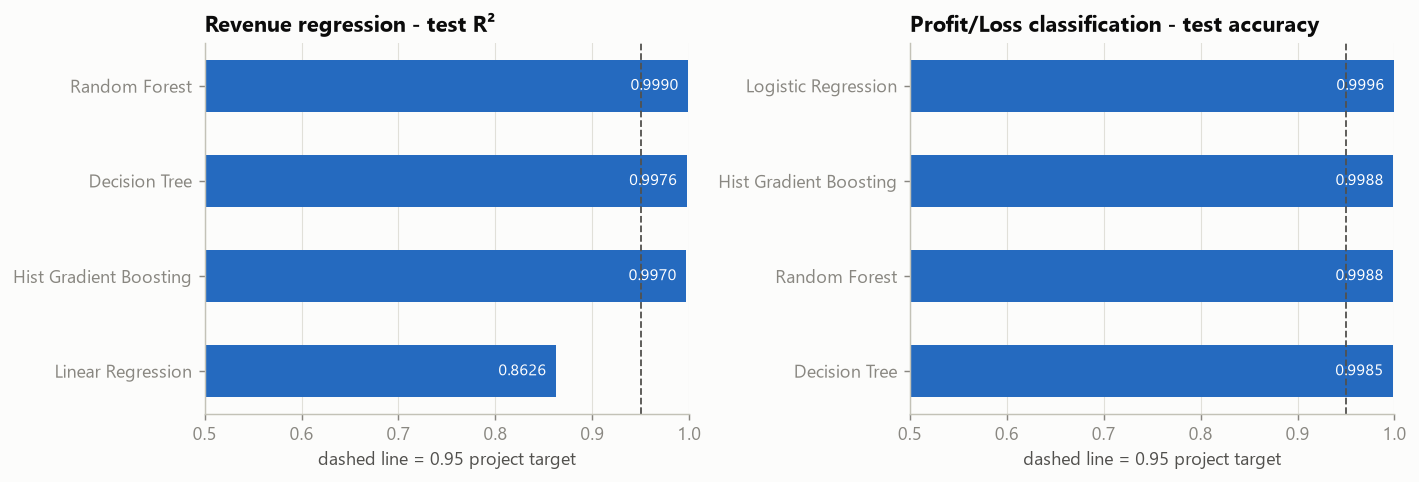

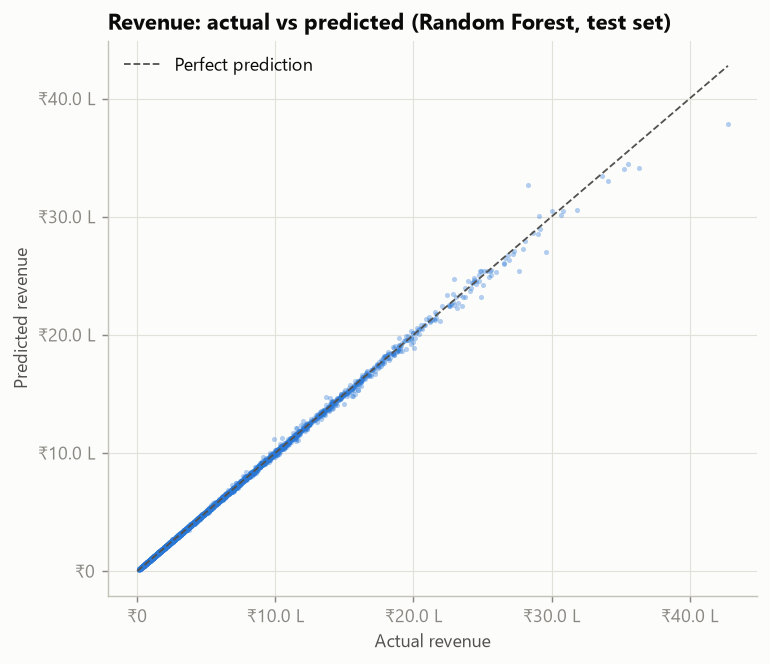

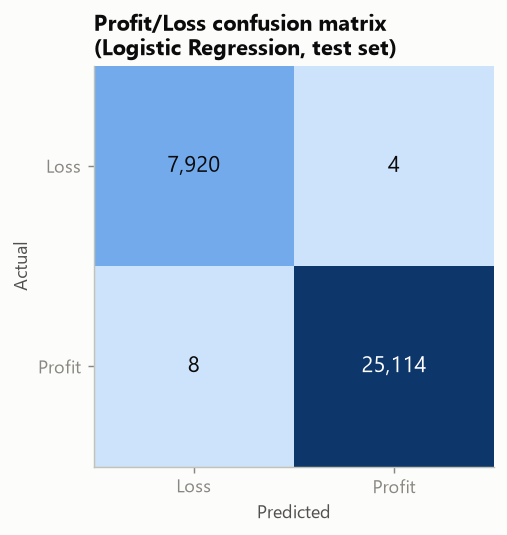

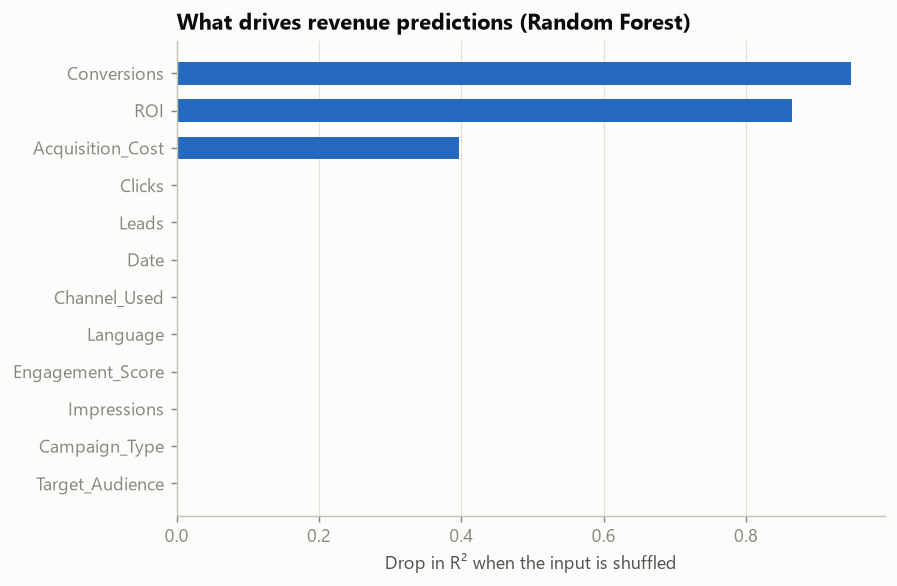

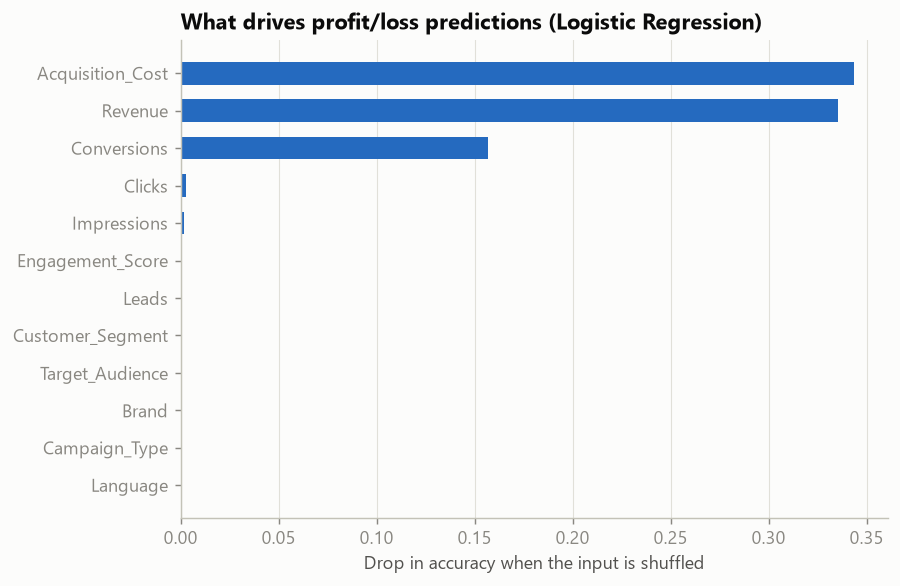

In [18]:
for f in ['model_comparison', 'model_revenue_actual_vs_pred', 'model_profit_confusion_matrix',
          'model_revenue_importance', 'model_profit_importance']:
    display(Image(str(C.FIGURES_DIR / f'{f}.png')))

In [19]:
meta = json.loads((C.MODELS_DIR / 'model_metadata.json').read_text())
meta['prelaunch_benchmark']

{'revenue_r2_without_roi': 0.7701352459824777,
 'profit_accuracy_without_revenue_roi': 0.9093687586999939,
 'profit_majority_baseline': 0.7602190885432427}

## 7. Using the saved models

In [20]:
reg_model = joblib.load(C.MODELS_DIR / 'revenue_regressor.joblib')
clf_model = joblib.load(C.MODELS_DIR / 'profit_classifier.joblib')
sample = feat.sample(5, random_state=1)
out = sample[['Campaign_ID','Brand','Revenue','ROI','Profit_Status']].copy()
out['Pred_Revenue'] = reg_model.predict(sample[meta['regression']['inputs']]).round(0)
out['Pred_Profit_Prob'] = clf_model.predict_proba(sample[meta['classification']['inputs']])[:, 1].round(3)
out

,Campaign_ID,Brand,Revenue,ROI,Profit_Status,Pred_Revenue,Pred_Profit_Prob
57543,PU-CMP-3516,Purplle,892700.0,2.26,Profit,887951.0,1.0
65043,PU-CMP-11075,Purplle,379155.0,0.36,Profit,378152.0,1.0
17276,NY-CMP-18422,Nykaa,86994.0,-0.65,Loss,88136.0,0.0
103842,PU-CMP-50202,Purplle,115584.0,-0.19,Loss,115286.0,0.0
39867,NY-CMP-41214,Nykaa,55876.0,-0.66,Loss,55789.0,0.0


See `reports/EDA_Report.md` and `reports/Model_Evaluation_Report.md` for insights and recommendations.